# **Parkinson Disease_Prediction_SVM model**

## **1. Load the Parkinson Disease Dataset**

In [33]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV

In [4]:
# Load Parkinson's dataset
parkinson_df = pd.read_csv("parkinson disease.csv")

# Display first five rows
parkinson_df.head()

,id,gender,PPE,EEG,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [7]:
parkinson_df.shape

(756, 755)

In [6]:
parkinson_df.describe()

,id,gender,PPE,EEG,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
count,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,...,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000,756.000000
mean,125.500000,0.515873,0.746284,0.700414,0.489058,323.972222,322.678571,0.006360,0.000383,0.002324,...,26.237251,22.840337,18.587888,13.872018,12.218953,12.375335,14.799230,14.751559,31.481110,0.746032
std,72.793721,0.500079,0.169294,0.069718,0.137442,99.219059,99.402499,0.001826,0.000728,0.002628,...,42.220693,32.626464,25.537464,20.046029,17.783642,16.341665,15.722502,14.432979,34.230991,0.435568
min,0.000000,0.000000,0.041551,0.543500,0.154300,2.000000,1.000000,0.002107,0.000011,0.000210,...,1.509800,1.531700,1.582900,1.747200,1.789500,1.628700,1.861700,1.955900,2.364000,0.000000
25%,62.750000,0.000000,0.762833,0.647053,0.386537,251.000000,250.000000,0.005003,0.000049,0.000970,...,2.408675,3.452800,3.354825,3.077450,2.937025,3.114375,3.665925,3.741275,3.948750,0.000000
50%,125.500000,1.000000,0.809655,0.700525,0.484355,317.000000,316.000000,0.006048,0.000077,0.001495,...,5.586300,7.062750,6.077400,4.770850,4.300450,4.741450,6.725700,7.334250,10.637250,1.000000
75%,188.250000,1.000000,0.834315,0.754985,0.586515,384.250000,383.250000,0.007528,0.000171,0.002520,...,28.958075,29.830850,21.944050,13.188000,10.876150,12.201325,21.922050,22.495175,61.125325,1.000000
max,251.000000,1.000000,0.907660,0.852640,0.871230,907.000000,905.000000,0.012966,0.003483,0.027750,...,239.788800,203.311300,121.542900,102.207000,85.571700,73.532200,62.007300,57.544300,156.423700,1.000000


In [16]:
# Define features and target
X = parkinson_df.drop(columns=["id", "class"])
y = parkinson_df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

## **2. Understand and Preprocess the Data**

In [10]:
# Check class distribution
print(y.value_counts())

class
1    564
0    192
Name: count, dtype: int64


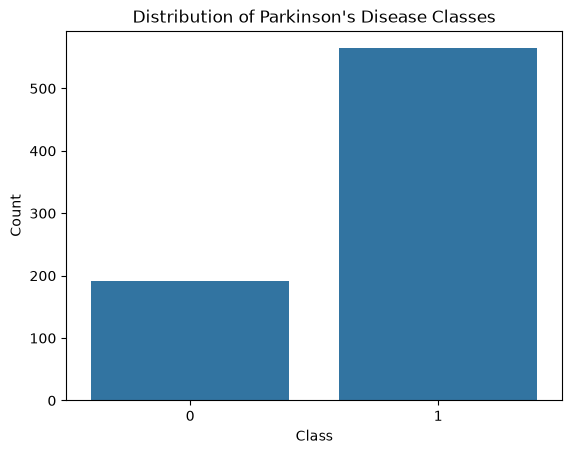

In [15]:
sns.countplot(data=parkinson_df, x='class')
plt.title("Distribution of Parkinson's Disease Classes")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [19]:
# Check missing values
print("Total missing values:", parkinson_df.isnull().sum().sum())

Total missing values: 0


In [20]:
# Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Training data shape: (604, 753)
Testing data shape: (152, 753)


## **3. Build and Train the SVM Model**

In [23]:
# Initialize SVM with RBF kernel
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

In [24]:
# Train SVM model
svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


## **4. Make Predictions and Evaluate the Model**

In [25]:
# Predict on the test set
y_pred = svm_model.predict(X_test_scaled)

In [26]:
# Classification report
print("SVM Classification Report:")
print(classification_report(y_test, y_pred))

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.41      0.54        39
           1       0.83      0.96      0.89       113

    accuracy                           0.82       152
   macro avg       0.81      0.69      0.72       152
weighted avg       0.82      0.82      0.80       152

Accuracy: 0.8223684210526315


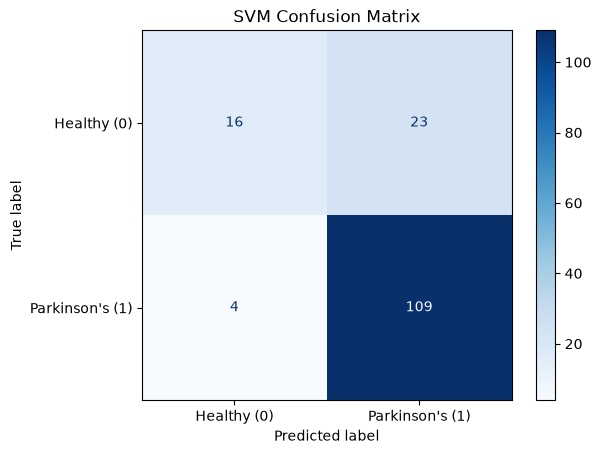

In [28]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy (0)", "Parkinson's (1)"])

disp.plot(cmap="Blues", values_format="d")
plt.title("SVM Confusion Matrix")
plt.show()

## **5. Tuning the Model with GridSearchCV with Class Balancing**

In [29]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

class
1    451
0    153
Name: count, dtype: int64
class
1    74.668874
0    25.331126
Name: proportion, dtype: float64


### **5.1 Define and Tune the SVM Model**

In [31]:
# Define hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 0.01, 0.1],
    'class_weight': [None, 'balanced']}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    cv=5,
    scoring='balanced_accuracy',
    n_jobs=-1)

# Train the model
grid_search.fit(X_train_scaled, y_train)

# Display best parameters
print("Best Parameters:", grid_search.best_params_)
print("Best CV Balanced Accuracy:", grid_search.best_score_)

Best Parameters: {'C': 10, 'class_weight': None, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Balanced Accuracy: 0.7879219346961281


In [ ]:
# Evaluate the Tuned SVM Model

# Get best model
best_svm = grid_search.best_estimator_

# Make predictions
y_pred_tuned = best_svm.predict(X_test_scaled)

# Evaluate performance
print("Tuned SVM Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Tuned SVM Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned SVM Accuracy: 0.9013157894736842
Tuned SVM Balanced Accuracy: 0.8328795098706603

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.69      0.78        39
           1       0.90      0.97      0.94       113

    accuracy                           0.90       152
   macro avg       0.90      0.83      0.86       152
weighted avg       0.90      0.90      0.90       152



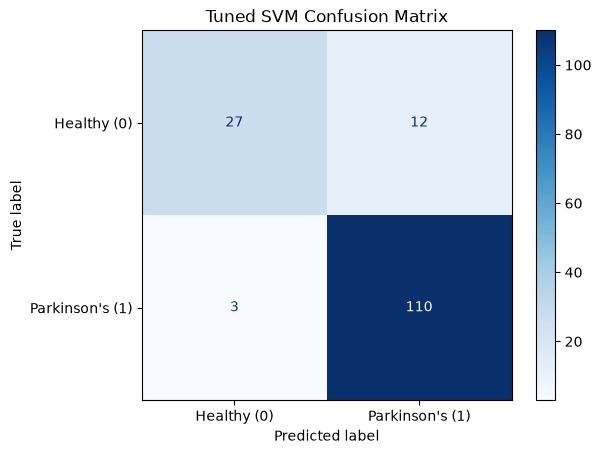

In [ ]:
# Visualize the Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    labels=[0, 1],
    display_labels=["Healthy (0)", "Parkinson's (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned SVM Confusion Matrix")
plt.show()

In [ ]:
# Compare Original and Tuned SVM Models

from sklearn.metrics import recall_score

comparison = pd.DataFrame({
    'Model': ['Original SVM', 'Tuned SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tuned)
    ],
    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred_tuned)
    ],
    'Parkinson Recall': [
        recall_score(y_test, y_pred, pos_label=1),
        recall_score(y_test, y_pred_tuned, pos_label=1)
    ],
    'Healthy Specificity': [
        recall_score(y_test, y_pred, pos_label=0),
        recall_score(y_test, y_pred_tuned, pos_label=0)
    ]
})

comparison.round(4)

,Model,Accuracy,Balanced Accuracy,Parkinson Recall,Healthy Specificity
0,Original SVM,0.8224,0.6874,0.9646,0.4103
1,Tuned SVM,0.9013,0.8329,0.9735,0.6923
